<a href="https://colab.research.google.com/github/Apekshagaonkar/ai-systems-notebooks/blob/main/week3_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 3 — Should I Go for a Run Tomorrow?
### Classification from first principles, then saving the model

Last week the answer was a **number**: *how hot will it get?*

This week the answer is a **label**: *good day for a run, or skip?*



## Setup — run this first
Loads the tools and three years of daily weather for one city, already labeled **good** (1) or **skip** (0).

In [ ]:
import json, os, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

NUMERIC = ["temperature_2m_max", "temperature_2m_min", "precipitation_sum", "wind_speed_10m_max"]

def load_weather():
    """Three years of daily weather (generated so everyone gets identical data)."""
    rng = np.random.default_rng(0)
    n = 1096
    dates = pd.date_range("2023-01-01", periods=n, freq="D")
    season_wave = -np.cos(2 * np.pi * (dates.dayofyear.values - 15) / 365)
    swings = np.zeros(n)
    shocks = rng.normal(0, 3.5, n)
    for i in range(1, n):
        swings[i] = 0.6 * swings[i - 1] + shocks[i]
    t_max = 17 + 9 * season_wave + swings
    t_min = t_max - rng.uniform(6, 12, n)
    wet = rng.random(n) < 0.32 - 0.12 * season_wave
    rain = np.where(wet, rng.gamma(1.2, 4, n), 0.0)
    wind = np.clip(rng.normal(17, 8, n), 2, None)
    month = dates.month.values
    season = np.select([np.isin(month, [12, 1, 2]), np.isin(month, [3, 4, 5]), np.isin(month, [6, 7, 8])],
                       ["winter", "spring", "summer"], "autumn")
    # The label rule: mild (4–28 °C), dry (< 1 mm), not too windy (< 24 km/h)
    good = ((t_max >= 4) & (t_max <= 28) & (rain < 1.0) & (wind < 24)).astype(int)
    return pd.DataFrame({
        "date": dates,
        "temperature_2m_max": t_max.round(1), "temperature_2m_min": t_min.round(1),
        "precipitation_sum": rain.round(1), "wind_speed_10m_max": wind.round(1),
        "season": season, "good": good,
    })

weather = load_weather()
print(f"{len(weather)} days loaded")
weather.head()

1096 days loaded


,date,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max,season,good
0,2023-01-01,8.3,-2.7,0.0,26.7,winter,0
1,2023-01-02,7.8,-1.1,0.0,2.9,winter,1
2,2023-01-03,10.2,0.8,8.6,13.1,winter,0
3,2023-01-04,9.7,1.4,2.1,24.8,winter,0
4,2023-01-05,7.2,-3.3,23.7,30.2,winter,0


---
## 0. A yes/no question  

Last week: *"It's 6 a.m., how hot will it get?"* The answer was a number like 18.1 °C. That's **regression**.

This week: *"Should I go for a run tomorrow?"* The answer is one of two labels: **good** or **skip**. That's **classification**.

Same weather, same `create → fit → predict`. Only the question changed.

---
## 1. Meet the data  
Four weather numbers, plus the **season**, plus the label we want to predict.

In [ ]:
counts = weather["good"].value_counts().sort_index()
print(f"skip (0): {counts[0]} days   good (1): {counts[1]} days   →  {weather['good'].mean():.0%} good")

print("\nTypical good day vs typical skip day:")
weather.groupby("good")[NUMERIC].mean().round(1).rename(index={0: "skip", 1: "good"}).rename_axis(None)

skip (0): 525 days   good (1): 571 days   →  52% good

Typical good day vs typical skip day:


,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max
skip,15.9,7.0,3.0,20.5
good,17.2,8.3,0.0,14.4


---
## 2. Ask the neighbours  

**First principle:** to decide about a new day, find the past days that looked most like it and let them **vote**. That's **K-Nearest Neighbours (KNN)**.

Here's tomorrow's forecast. Let's do KNN by hand.

In [ ]:
tomorrow = pd.DataFrame([{"temperature_2m_max": 21.0, "temperature_2m_min": 12.0,
                          "precipitation_sum": 0.0, "wind_speed_10m_max": 12.0, "season": "spring"}])
print("Tomorrow's forecast:")
print(tomorrow.to_string(index=False))


# Distance = how different each past day is from tomorrow, across the four numbers
diff = weather[NUMERIC].values - tomorrow[NUMERIC].values
weather["distance"] = np.sqrt((diff ** 2).sum(axis=1))

print("\n")
neighbours = weather.nsmallest(5, "distance")
show = neighbours[["date", *NUMERIC, "good", "distance"]].copy()
show["date"] = show["date"].dt.date
print(show.round(1).to_string(index=False))
print(f"\nVotes for good: {neighbours['good'].sum()} of 5  →  prediction: {'GOOD' if neighbours['good'].sum() >= 3 else 'SKIP'}")
weather = weather.drop(columns="distance")

Tomorrow's forecast:
 temperature_2m_max  temperature_2m_min  precipitation_sum  wind_speed_10m_max season
               21.0                12.0                0.0                12.0 spring


      date  temperature_2m_max  temperature_2m_min  precipitation_sum  wind_speed_10m_max  good  distance
2024-08-11                20.6                11.9                0.0                11.6     1       0.6
2025-05-30                20.7                12.8                0.0                12.6     1       1.0
2025-05-20                20.9                10.4                0.0                12.4     1       1.7
2023-06-13                21.1                13.9                0.0                11.6     1       1.9
2024-10-14                20.5                11.7                0.0                13.9     1       2.0

Votes for good: 5 of 5  →  prediction: GOOD


Now the same thing with scikit-learn, scored on hidden days like last week:

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

X = weather[NUMERIC + ["season"]]
y = weather["good"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

no_scaling = ColumnTransformer([
    ("num", "passthrough", NUMERIC),          # numbers used as-is
    ("cat", OneHotEncoder(), ["season"]),      # season → one column per season (Chapter 3)
])
knn_raw = Pipeline([("preprocess", no_scaling), ("classifier", KNeighborsClassifier(n_neighbors=5))])
knn_raw.fit(X_train, y_train)
print(f"KNN, no scaling: accuracy on hidden days = {knn_raw.score(X_test, y_test):.3f}")

KNN, no scaling: accuracy on hidden days = 0.923


---
## 3. The ruler problem  

KNN adds up raw differences. But the four columns are measured in **different units with different spreads**:

In [ ]:
print("How much each feature typically varies (standard deviation):")
print(weather[NUMERIC].std().round(1).to_string())

a = dict(temperature_2m_max=20, temperature_2m_min=11, precipitation_sum=0.0, wind_speed_10m_max=12)
b = dict(a, precipitation_sum=6.0)      # same day, but 6 mm of rain: a soggy run!
c = dict(a, temperature_2m_max=26)      # same day, but 6 °C warmer: still a fine run
dist = lambda p, q: np.sqrt(sum((p[k] - q[k]) ** 2 for k in NUMERIC))
print(f"\nDistance to a rainy version of the day:   {dist(a, b):.1f}")
print(f"Distance to a warmer version of the day:  {dist(a, c):.1f}")

How much each feature typically varies (standard deviation):
temperature_2m_max    7.4
temperature_2m_min    7.6
precipitation_sum     3.3
wind_speed_10m_max    7.7

Distance to a rainy version of the day:   6.0
Distance to a warmer version of the day:  6.0


❓ **6 mm of rain changes the label. 6 °C warmer doesn't. Yet KNN thinks they're equally different. Why?**

**Fix: put every feature on the same ruler.** `StandardScaler` turns each feature into "how many standard deviations from its average" (mean 0, std 1). Now 1 unit of rain matters as much as 1 unit of temperature.

⚠️ **Fit the scaler on the training days only**, then apply it to both. If it sees the test days while learning the averages, information leaks from the exam into the study notes, and scores look better than they really are. A **Pipeline** does this for us automatically.

**And `season`?** It's a word. Numbering it (winter = 0, spring = 1…) would invent a fake order ("autumn is 3× spring"). **One-hot encoding** makes one 0/1 column per season instead.

In [ ]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC),        # same ruler for every number
    ("cat", OneHotEncoder(), ["season"]),      # one column per season
])
knn = Pipeline([("preprocess", preprocess), ("classifier", KNeighborsClassifier(n_neighbors=5))])
knn.fit(X_train, y_train)                      # scaler learns averages from TRAINING days only

print(f"KNN, no scaling:   {knn_raw.score(X_test, y_test):.3f}")
print(f"KNN, with scaling: {knn.score(X_test, y_test):.3f}")
print("\nWhat season looks like after one-hot encoding:")
print(pd.DataFrame(preprocess.named_transformers_["cat"].transform(X_train[["season"]].head(3)).toarray(),
                   columns=preprocess.named_transformers_["cat"].get_feature_names_out()).astype(int))

KNN, no scaling:   0.923
KNN, with scaling: 0.955

What season looks like after one-hot encoding:
   season_autumn  season_spring  season_summer  season_winter
0              0              1              0              0
1              0              0              0              1
2              1              0              0              0


---
## 4. A weighted vote: Logistic Regression

**First principle:** give each feature a **weight**, add them up into a score, then squash the score into a probability between 0 and 1 with the **sigmoid** curve. Above 0.5 → good.

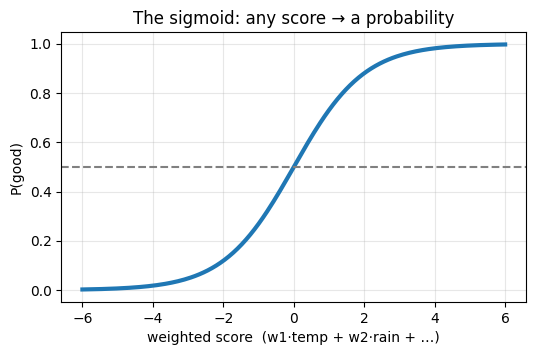

In [ ]:
z = np.linspace(-6, 6, 200)
plt.figure(figsize=(6, 3.5))
plt.plot(z, 1 / (1 + np.exp(-z)), linewidth=3)
plt.axhline(0.5, color="grey", linestyle="--")
plt.xlabel("weighted score  (w1·temp + w2·rain + …)"); plt.ylabel("P(good)")
plt.title("The sigmoid: any score → a probability"); plt.grid(alpha=0.3); plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression

logreg = Pipeline([("preprocess", preprocess), ("classifier", LogisticRegression(max_iter=1000))])
logreg.fit(X_train, y_train)
print(f"Logistic Regression accuracy: {logreg.score(X_test, y_test):.3f}   (KNN: {knn.score(X_test, y_test):.3f})")

names = logreg.named_steps["preprocess"].get_feature_names_out()
weights = pd.Series(logreg.named_steps["classifier"].coef_[0], index=names).round(2)
print("\nWeights (on scaled features):")
print(weights.loc[[f"num__{c}" for c in NUMERIC]].to_string())

p = logreg.predict_proba(tomorrow)[0, 1]
print(f"\nTomorrow: P(good) = {p:.2f}")

Logistic Regression accuracy: 0.868   (KNN: 0.955)

Weights (on scaled features):
num__temperature_2m_max    0.05
num__temperature_2m_min   -0.19
num__precipitation_sum    -6.09
num__wind_speed_10m_max   -1.64

Tomorrow: P(good) = 0.94


### The mystery of the missing temperature

The label rule says a good day must be **mild**. So why did Logistic Regression give temperature almost no weight, and why does it score 0.87 when KNN scores 0.96?

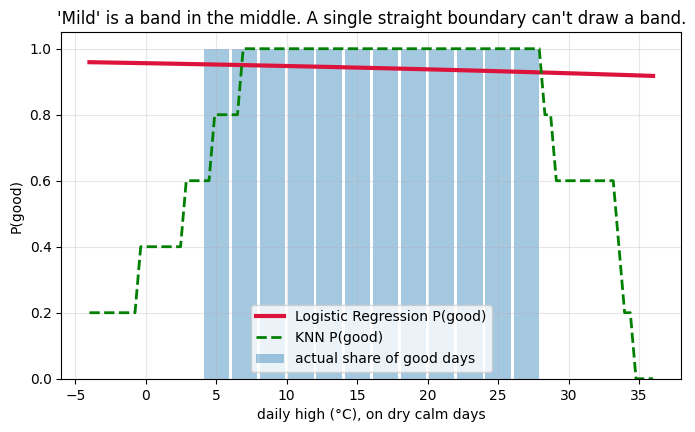

In [ ]:
# Look only at dry, calm days, so temperature is the only thing that varies
calm = weather[(weather["precipitation_sum"] < 1) & (weather["wind_speed_10m_max"] < 24)]
bins = np.arange(-4, 38, 2)
rate = calm.groupby(pd.cut(calm["temperature_2m_max"], bins), observed=True)["good"].mean()
mid = [iv.mid for iv in rate.index]

temps = np.linspace(-4, 36, 100)
probe = pd.DataFrame({"temperature_2m_max": temps, "temperature_2m_min": temps - 9,
                      "precipitation_sum": 0.0, "wind_speed_10m_max": 12.0, "season": "spring"})

plt.figure(figsize=(8, 4.5))
plt.bar(mid, rate.values, width=1.8, alpha=0.4, label="actual share of good days")
plt.plot(temps, logreg.predict_proba(probe)[:, 1], color="crimson", linewidth=3, label="Logistic Regression P(good)")
plt.plot(temps, knn.predict_proba(probe)[:, 1], color="green", linewidth=2, linestyle="--", label="KNN P(good)")
plt.xlabel("daily high (°C), on dry calm days"); plt.ylabel("P(good)")
plt.title("'Mild' is a band in the middle. A single straight boundary can't draw a band.")
plt.legend(loc="lower center"); plt.grid(alpha=0.3); plt.show()

---
## 5. Two kinds of wrong  

Accuracy counts mistakes but doesn't say **which kind**. Think of a rapid medical test: a false alarm and a missed case are very different mistakes. Same here:

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

pred = logreg.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print("                    actually good   actually skip")
print(f"called GOOD      TP = {tp:3d}          FP = {fp:3d}   ← sent out in bad weather")
print(f"called SKIP      FN = {fn:3d}          TN = {tn:3d}")
print(f"                   ↑ missed a good day")
print(f"\nPrecision = TP / (TP + FP) = {precision_score(y_test, pred):.2f}   of days we called good, how many were")
print(f"Recall    = TP / (TP + FN) = {recall_score(y_test, pred):.2f}   of truly good days, how many we caught")

                    actually good   actually skip
called GOOD      TP = 106          FP =  20   ← sent out in bad weather
called SKIP      FN =   9          TN =  85
                   ↑ missed a good day

Precision = TP / (TP + FP) = 0.84   of days we called good, how many were
Recall    = TP / (TP + FN) = 0.92   of truly good days, how many we caught


### Probabilities let you choose the trade-off
The model says "good" when P(good) ≥ 0.5. Nothing forces 0.5. If getting caught in rain is worse than missing a run, demand more confidence:

In [ ]:
probs = logreg.predict_proba(X_test)[:, 1]
print("threshold   precision   recall   false alarms   missed good days")
for t in [0.3, 0.5, 0.7]:
    p_t = (probs >= t).astype(int)
    _, fp_t, fn_t, _ = confusion_matrix(y_test, p_t).ravel()
    print(f"   {t:.1f}        {precision_score(y_test, p_t):.2f}       {recall_score(y_test, p_t):.2f}         {fp_t:3d}            {fn_t:3d}")

threshold   precision   recall   false alarms   missed good days
   0.3        0.76       0.99          36              1
   0.5        0.84       0.92          20              9
   0.7        0.88       0.76          12             28


---
## 6. Ship it

KNN scored higher. So why do the slides deploy Logistic Regression? Compare what each one hands you:

In [ ]:
import joblib
os.makedirs("models", exist_ok=True)
joblib.dump(knn, "models/knn.pkl")
joblib.dump(logreg, "models/weather_classifier.pkl")

knn_probs = sorted(set(np.round(knn.predict_proba(X_test)[:, 1], 2)))
print(f"KNN probabilities can only be: {knn_probs}   (votes out of 5)")
print(f"LogReg probabilities, e.g.:    {np.round(probs[:6], 2).tolist()}")
print(f"\nFile size  KNN:    {os.path.getsize('models/knn.pkl') / 1024:6.1f} KB  (carries every training day)")
print(f"File size  LogReg: {os.path.getsize('models/weather_classifier.pkl') / 1024:6.1f} KB  (just a few weights)")

KNN probabilities can only be: [np.float64(0.0), np.float64(0.2), np.float64(0.4), np.float64(0.6), np.float64(0.8), np.float64(1.0)]   (votes out of 5)
LogReg probabilities, e.g.:    [0.0, 0.86, 0.98, 0.94, 0.93, 0.78]

File size  KNN:     132.1 KB  (carries every training day)
File size  LogReg:    3.5 KB  (just a few weights)


### Save the whole pipeline, plus a label for the box
Save the **pipeline** (scaler + encoder + model together), not just the classifier, or the next person feeds it unscaled numbers. And write a small metadata file, because a `.pkl` is an unreadable binary blob.

In [ ]:
metadata = {
    "model": "LogisticRegression in a Pipeline (StandardScaler + OneHotEncoder)",
    "features_in_order": NUMERIC + ["season"],
    "label_rule": "good = 4 <= temperature_2m_max <= 28 and precipitation_sum < 1 and wind_speed_10m_max < 24",
    "test_accuracy": round(logreg.score(X_test, y_test), 3),
    "test_precision": round(precision_score(y_test, pred), 3),
    "test_recall": round(recall_score(y_test, pred), 3),
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "joblib": joblib.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}
with open("models/weather_classifier.json", "w") as f:
    json.dump(metadata, f, indent=2)

# Later, somewhere else (next week: inside your component)
clf = joblib.load("models/weather_classifier.pkl")
print(f"Reloaded model says tomorrow is: {'GOOD' if clf.predict(tomorrow)[0] else 'SKIP'} "
      f"(P(good) = {clf.predict_proba(tomorrow)[0, 1]:.2f})")
print(json.dumps(metadata, indent=2))

Reloaded model says tomorrow is: GOOD (P(good) = 0.94)
{
  "model": "LogisticRegression in a Pipeline (StandardScaler + OneHotEncoder)",
  "features_in_order": [
    "temperature_2m_max",
    "temperature_2m_min",
    "precipitation_sum",
    "wind_speed_10m_max",
    "season"
  ],
  "label_rule": "good = 4 <= temperature_2m_max <= 28 and precipitation_sum < 1 and wind_speed_10m_max < 24",
  "test_accuracy": 0.868,
  "test_precision": 0.841,
  "test_recall": 0.922,
  "versions": {
    "python": "3.13.16",
    "scikit-learn": "1.6.1",
    "joblib": "1.6.0",
    "numpy": "2.1.3",
    "pandas": "2.2.3"
  }
}


⚠️ **Only load `.pkl` files you trust.** Loading a pickle can run code hidden inside it, so never load a model file from an unknown source.

---
## Wrap-up  

1. **Classification** predicts a label; same `create → fit → predict`.
2. **KNN** = let the most similar days vote. It needs **scaling**, or big-range features drown out the important ones.
3. **Fit preprocessing on training data only**; a **Pipeline** does it for you and travels with the model.
4. **Logistic Regression** = weighted score → sigmoid → probability. One straight boundary, so it can't draw a "mild" band.
5. **Precision and recall** separate the two kinds of mistake; the **threshold** trades one for the other.
6. **Deploy** the model that fits the job: small, explainable, with probabilities. Save the whole pipeline + metadata.

### Next week
You saved a model to disk. Next week you wrap it in a reusable component with a clean `predict()` method and tests.

### Think about before next time
- Why must the scaler be fit on training days only?
- Your app should never send people out in the rain. Raise or lower the threshold?
- What one feature would let Logistic Regression learn "mild"?